# 04 — Preprocessing, class imbalance and feature selection

**Stages 5–7.** This notebook turns the EDA decisions into leakage-safe pipelines, compares five ways of handling the 6.6% minority class, and decides the final feature set with group ablations.

Everything here is scored with **walk-forward cross-validation inside the training period**. Each validation fold is one month (Oct 2017 → Feb 2018). Each fold trains only on earlier orders whose promised day had already passed, the same maturity rule as the final split. The validation and test periods are still untouched.

In [1]:
import sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, f1_score, precision_score, recall_score
from olist import config as C
from olist.evaluate import best_f1_threshold
from olist.features import FEATURES, DROPPED_AFTER_ABLATION, model_features
from olist.modeling import (load_task_a, task_a_sets, walk_forward_folds, walk_forward_predict, linear_preprocessor,
                            tree_preprocessor, make_model, smotenc_sampler)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"04_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"; RESULTS.mkdir(parents=True, exist_ok=True)

pop = load_task_a(); S = task_a_sets(pop)
TP, TRAIN = S["train_period"], S["train"]
FULL = list(FEATURES.index)                       # all 57 registered features
MONTHS = ["2017-10", "2017-11", "2017-12", "2018-01", "2018-02"]
folds = walk_forward_folds(TP, MONTHS)
fold_tab = pd.DataFrame([{"val_month": m, "train_rows": len(tr), "train_last_purchase": TP.order_purchase_timestamp.iloc[tr].max().date(),
                          "val_rows": len(va), "val_late_%": round(TP.late_day.iloc[va].mean() * 100, 2)}
                         for m, (tr, va) in zip(MONTHS, folds)]).set_index("val_month")
fold_tab

,train_rows,train_last_purchase,val_rows,val_late_%
val_month,,,,
2017-10,23141,2017-09-20,4478,4.18
2017-11,27153,2017-10-19,7288,12.40
2017-12,31684,2017-11-17,5513,7.46
2018-01,38762,2017-12-12,7069,5.70
2018-02,44227,2018-01-16,6555,14.13


The training rows of each fold stop about two weeks before the validation month starts. Orders placed in those last weeks were not yet resolved at the fold's cutoff, so they are purged. The validation late rate moves between 5.7% and 14.1%, so fold scores are compared within a fold, never as raw numbers across folds.

## 1. Preprocessing pipelines

| Feature type | Linear models (logistic regression) | Tree models (CART, Random Forest, LightGBM) |
|---|---|---|
| Skewed numerics (`LOG_FEATURES`, 25) | log1p → median impute + missing flag → winsorise 1/99% → standardise | raw, NaN passed through |
| Other numerics | median impute + missing flag → winsorise → standardise | raw |
| Binary flags | passthrough | passthrough |
| Low-cardinality categoricals (states, payment, weekdays, month) | one-hot, rare levels (< 30 rows) pooled | states → target encoding; weekday/month → integer codes; payment → ordinal |
| `main_category` (74 levels) | cross-fitted target encoding → standardise | cross-fitted target encoding |

Every statistic (median, quantile, mean, category level, target mean) is learned inside `Pipeline.fit` on training rows only. `TargetEncoder` additionally cross-fits *within* the training rows, so a row's own label never feeds its own encoding.

In [2]:
lin = linear_preprocessor(FULL).fit(TRAIN[FULL], TRAIN.late_day)
Xl = lin.transform(S["val"][FULL])
groups = {name: len(trans.get_feature_names_out()) if hasattr(trans, "get_feature_names_out") else len(cols)
          for name, trans, cols in lin.transformers_ if name != "remainder"}
print("linear design matrix:", Xl.shape, "| columns per block:", groups, "| NaN after transform:", int(Xl.isna().sum().sum()))
tree = tree_preprocessor(FULL).fit(TRAIN[FULL], TRAIN.late_day)
Xt = tree.transform(S["val"][FULL])
print("tree design matrix:", Xt.shape, "| same names as the registry:", sorted(Xt.columns) == sorted(FULL))

# proof that statistics come from training rows only
imp = lin.named_transformers_["log"].named_steps["impute"]
log_cols = lin.transformers_[0][2]
check = pd.DataFrame({"train_median(log1p)": imp.statistics_[:5],
                      "val_median(log1p)": np.log1p(S["val"][log_cols[:5]]).median().to_numpy()}, index=log_cols[:5])
print("\nImputer medians are the training medians, not the validation ones:"); display(check.round(3))
print("Standardised validation columns are NOT mean 0 / sd 1 (they were scaled with training statistics):")
Xl[log_cols[:5]].agg(["mean", "std"]).round(3)

linear design matrix: (13801, 129) | columns per block: {'log': 30, 'num': 17, 'bin': 10, 'onehot': 71, 'target': 1} | NaN after transform: 0
tree design matrix: (13801, 57) | same names as the registry: True

Imputer medians are the training medians, not the validation ones:


,train_median(log1p),val_median(log1p)
promised_days,3.219,3.178
promised_business_days,2.833,2.833
n_items,0.693,0.693
n_products,0.693,0.693
n_sellers,0.693,0.693


Standardised validation columns are NOT mean 0 / sd 1 (they were scaled with training statistics):


,promised_days,promised_business_days,n_items,n_products,n_sellers
mean,-0.282,-0.286,0.008,-0.005,0.041
std,1.127,1.147,1.017,0.987,1.173


## 2. Class imbalance: five strategies under walk-forward CV

Two learners (L2 logistic regression and LightGBM with default settings) are each trained five ways:

1. **none:** plain fit, the reference.
2. **class weights:** `class_weight="balanced"`, so errors on late orders cost about 14× more.
3. **undersample:** `RandomUnderSampler` to 1:1, applied to training folds only.
4. **SMOTE-NC:** synthetic minority rows to 1:1. One-hot levels, flags and weekday/month/payment codes are treated as categorical. It runs inside an `imblearn` pipeline, so validation folds are never resampled.
5. **threshold moving:** the *none* model, but the decision threshold for month *k* is the F1-optimal threshold found on month *k − 1*. This uses only past data.

Scores are averaged over the four folds Nov 2017 → Feb 2018. October serves only to pick the first moved threshold.

In [3]:
def variants(learner):
    base = make_model(learner, FULL)
    pre, clf = base.named_steps["pre"], base.named_steps["clf"]
    weighted = clone(base).set_params(clf__class_weight="balanced")
    under = ImbPipeline([("pre", clone(pre)), ("rus", RandomUnderSampler(sampling_strategy=1.0, random_state=C.SEED)), ("clf", clone(clf))])
    smote_steps = [("pre", clone(pre))]
    if learner != "logreg":                     # tree preprocessing keeps NaN; SMOTE needs complete rows
        smote_steps.append(("impute", SimpleImputer(strategy="median").set_output(transform="pandas")))
    smote_steps += [("smote", smotenc_sampler(extra_categorical=("purchase_dow", "promise_dow", "purchase_month", "main_payment_type"))),
                    ("clf", clone(clf))]
    return {"none": base, "class weights": weighted, "undersample": under, "SMOTE-NC": ImbPipeline(smote_steps)}

y_folds = [TP.late_day.to_numpy()[va].astype(int) for _, va in folds]
imb_rows, imb_preds = [], {}
for learner in ["logreg", "lgbm"]:
    for strat, est in variants(learner).items():
        t = time.perf_counter()
        preds = walk_forward_predict(est, TP, folds, FULL, n_jobs=5)
        imb_preds[(learner, strat)] = preds
        for k in range(1, len(folds)):
            y, p = y_folds[k], preds[k]
            imb_rows.append({"learner": learner, "strategy": strat, "fold": MONTHS[k], "pr_auc": average_precision_score(y, p),
                             "roc_auc": roc_auc_score(y, p), "brier": brier_score_loss(y, p), "threshold": 0.5,
                             "precision": precision_score(y, p >= 0.5, zero_division=0), "recall": recall_score(y, p >= 0.5),
                             "f1": f1_score(y, p >= 0.5), "flagged_%": (p >= 0.5).mean() * 100})
        print(f"{learner:7s} {strat:14s} {time.perf_counter()-t:6.1f}s")
    # threshold moving on the unweighted model: threshold for month k chosen on month k-1
    preds = imb_preds[(learner, "none")]
    for k in range(1, len(folds)):
        thr = best_f1_threshold(y_folds[k - 1], preds[k - 1])
        y, p = y_folds[k], preds[k]
        imb_rows.append({"learner": learner, "strategy": "threshold moving", "fold": MONTHS[k], "pr_auc": average_precision_score(y, p),
                         "roc_auc": roc_auc_score(y, p), "brier": brier_score_loss(y, p), "threshold": thr,
                         "precision": precision_score(y, p >= thr, zero_division=0), "recall": recall_score(y, p >= thr),
                         "f1": f1_score(y, p >= thr), "flagged_%": (p >= thr).mean() * 100})
imb = pd.DataFrame(imb_rows)
imb_summary = imb.groupby(["learner", "strategy"], sort=False).mean(numeric_only=True)
imb_summary.to_csv(RESULTS / "04_imbalance_strategies.csv")
imb_summary.round(3)

logreg  none             24.4s


logreg  class weights   322.8s


logreg  undersample       5.8s


logreg  SMOTE-NC        113.0s


lgbm    none             76.0s


lgbm    class weights     5.1s


lgbm    undersample       2.1s


lgbm    SMOTE-NC         22.4s


pr_auc  roc_auc  brier  threshold  precision  recall     f1  flagged_%
learner strategy                                                                                
logreg  none               0.167    0.653  0.092      0.500      0.028   0.001  0.001      0.035
        class weights      0.159    0.642  0.277      0.500      0.161   0.626  0.219     48.534
        undersample        0.156    0.640  0.200      0.500      0.177   0.440  0.212     29.352
        SMOTE-NC           0.167    0.638  0.423      0.500      0.069   0.680  0.124     62.944
        threshold moving   0.167    0.653  0.092      0.083      0.202   0.429  0.132     35.017
lgbm    none               0.161    0.631  0.092      0.500      0.075   0.002  0.004      0.039
        class weights      0.141    0.597  0.107      0.500      0.173   0.060  0.084      3.200
        undersample        0.157    0.622  0.217      0.500      0.157   0.477  0.228     32.125
        SMOTE-NC           0.128    0.576  0.136      0.500      0.070   0.126  0.055      9.785
        threshold moving   0.161    0.631  0.092      0.048      0.162   0.419  0.184     29.162

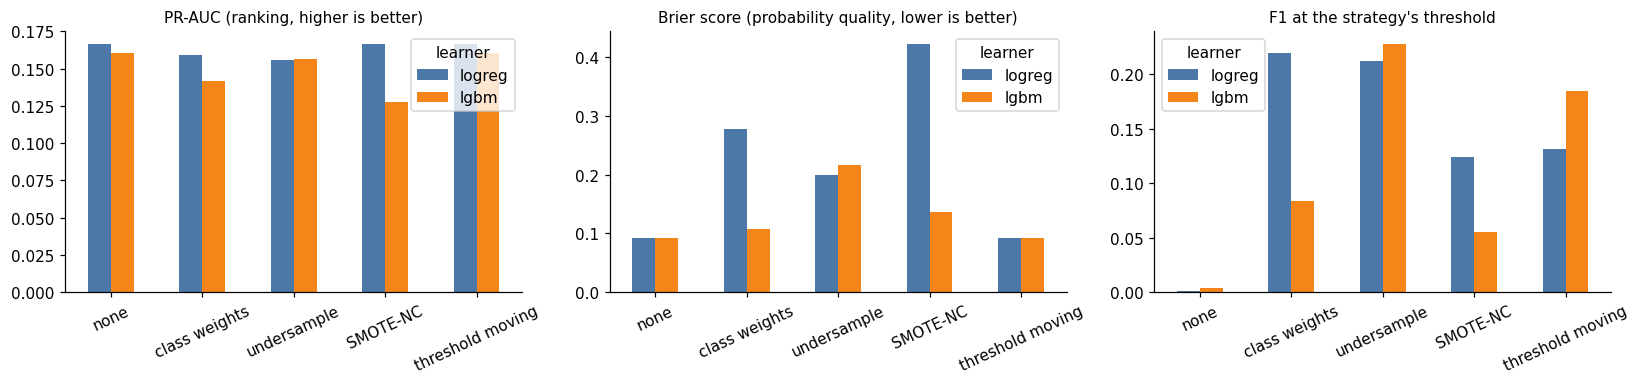

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
order = ["none", "class weights", "undersample", "SMOTE-NC", "threshold moving"]
for ax, metric, title in zip(axes, ["pr_auc", "brier", "f1"], ["PR-AUC (ranking, higher is better)",
                                                                 "Brier score (probability quality, lower is better)",
                                                                 "F1 at the strategy's threshold"]):
    piv = imb_summary[metric].unstack(0).reindex(order)
    piv.plot.bar(ax=ax, color=["#4C78A8", "#F58518"], rot=25); ax.set_title(title, fontsize=10); ax.set_xlabel("")
plt.tight_layout(); save("imbalance_strategies"); plt.show()

**Finding.** No resampling or weighting strategy ranks better than a plain fit. Logistic regression scores 0.167 PR-AUC plain, against 0.159 with class weights, 0.156 undersampled and 0.167 with SMOTE-NC. LightGBM scores 0.161 plain, against 0.141, 0.157 and 0.128. Every one of them **damages the probabilities**: for logistic regression the Brier score rises from 0.092 to between 0.20 and 0.42, because the model is trained as if half of all orders were late.

Their only apparent advantage is at the arbitrary 0.5 threshold. There a plain model flags almost nothing (F1 ≈ 0), while weighted or resampled models flag 30–63% of orders. Moving the plain model's threshold fixes this without touching the probabilities. However, a threshold copied from the previous month transfers poorly when the late rate jumps (Jan 5.7% → Feb 14.1%), which is why its F1 averages below the undersampled model's in these drifting folds.

**Decision.** Train on the natural class ratio (no resampling) and keep the probabilities honest. Imbalance is handled where it belongs: PR-AUC as the selection metric, a threshold chosen on validation (notebook 07), and a per-order cost rule on calibrated probabilities (notebook 08). Class weights stay in the hyperparameter searches (`class_weight`, `scale_pos_weight`), so the tuner can still choose them for a specific configuration if they improve ranking.

## 3. Feature selection: drop-one-group ablations

Each group is removed in turn and the four-fold walk-forward PR-AUC is compared with the full 57-feature set for both learners (plain fits, no resampling, following the decision above). A **negative Δ** means the group was helping. Every fold uses the same rows, so the per-fold differences are paired.

In [5]:
REDUNDANT = ["distance_km_min", "seller_prior_orders_min", "max_weight_g", "max_volume_cm3",
             "promised_business_days", "max_item_price", "seller_orders_30d_max"]
G = {
    "purchase_month": ["purchase_month"],
    "promise": FEATURES.index[FEATURES.group == "promise"].tolist(),
    "calendar (other)": [f for f in FEATURES.index[FEATURES.group == "calendar"] if f != "purchase_month"],
    "basket": FEATURES.index[FEATURES.group == "basket"].tolist(),
    "product": FEATURES.index[FEATURES.group == "product"].tolist(),
    "geography": FEATURES.index[FEATURES.group == "geography"].tolist(),
    "payment": FEATURES.index[FEATURES.group == "payment"].tolist(),
    "history: seller": [f for f in FEATURES.index if f.startswith("seller_")],
    "history: route + destination": ["route_late_rate_max", "route_resolved_n_min", "dest_state_late_rate", "dest_state_late_rate_90d"],
    "history: market": ["market_late_rate_30d", "market_resolved_30d"],
    "history: customer": ["customer_prior_orders"],
    "redundant near-duplicates": REDUNDANT,
}
abl_folds = folds[1:]
def cv_pr(learner, feats):
    preds = walk_forward_predict(make_model(learner, feats), TP, abl_folds, feats, n_jobs=4)
    return np.array([average_precision_score(y, p) for y, p in zip(y_folds[1:], preds)])

abl_rows = []
for learner in ["logreg", "lgbm"]:
    t = time.perf_counter()
    full = cv_pr(learner, FULL)
    abl_rows.append({"learner": learner, "removed": "(none: full set)", "n_features": len(FULL), "cv_pr_auc": full.mean(),
                     "delta": 0.0, "folds_worse": 0})
    for g, cols in G.items():
        feats = [f for f in FULL if f not in cols]
        s = cv_pr(learner, feats)
        abl_rows.append({"learner": learner, "removed": g, "n_features": len(feats), "cv_pr_auc": s.mean(),
                         "delta": (s - full).mean(), "folds_worse": int((s < full).sum())})
    print(f"{learner} ablations done in {time.perf_counter()-t:.0f}s")
abl = pd.DataFrame(abl_rows)
abl.to_csv(RESULTS / "04_ablation.csv", index=False)
abl_wide = abl.pivot(index="removed", columns="learner", values=["delta", "folds_worse"]).sort_values(("delta", "lgbm"))
abl_wide.round(4)

logreg ablations done in 142s


lgbm ablations done in 25s


delta         folds_worse       
learner                         lgbm  logreg        lgbm logreg
removed                                                        
geography                    -0.0162  0.0042         4.0    1.0
calendar (other)             -0.0128  0.0010         3.0    1.0
promise                      -0.0122 -0.0098         4.0    4.0
purchase_month               -0.0038 -0.0199         4.0    3.0
history: market              -0.0022  0.0019         2.0    2.0
history: route + destination -0.0012  0.0074         2.0    1.0
payment                      -0.0011 -0.0007         3.0    3.0
history: customer            -0.0005 -0.0000         3.0    2.0
(none: full set)              0.0000  0.0000         0.0    0.0
basket                        0.0006 -0.0026         2.0    4.0
redundant near-duplicates     0.0024  0.0009         2.0    1.0
history: seller               0.0026 -0.0003         1.0    2.0
product                       0.0048  0.0012         1.0    2.0

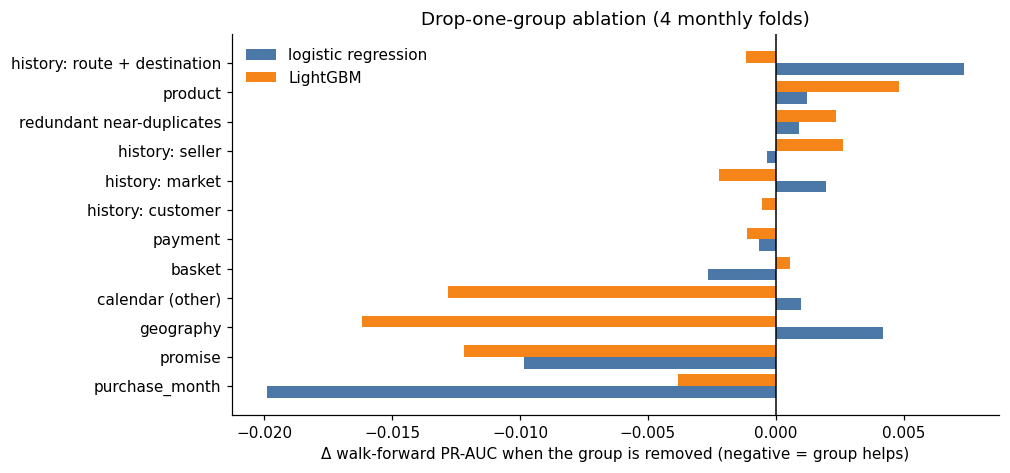

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
d = abl[abl.removed != "(none: full set)"].pivot(index="removed", columns="learner", values="delta")
d = d.loc[d.mean(axis=1).sort_values().index]
y = np.arange(len(d))
ax.barh(y - 0.2, d["logreg"], 0.4, label="logistic regression", color="#4C78A8")
ax.barh(y + 0.2, d["lgbm"], 0.4, label="LightGBM", color="#F58518")
ax.set_yticks(y, d.index); ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Δ walk-forward PR-AUC when the group is removed (negative = group helps)"); ax.legend(frameon=False)
ax.set_title("Drop-one-group ablation (4 monthly folds)")
save("ablation"); plt.show()

## 4. Two more selection lenses

**L1-regularised logistic regression** (pure lasso, strong penalty, fitted on the matured training set) shows which features carry no linear signal once the others are present. **Permutation importance** for LightGBM (fitted on the folds before Feb 2018, permuted on the Feb 2018 fold) shows which features the trees actually use out of time.

lasso (C=0.02): 35 of 129 design columns non-zero; 27 of 57 features fully zeroed:
  ['any_category_missing', 'any_zero_freight', 'customer_geo_imputed', 'customer_lat', 'customer_prior_orders', 'distance_km_max', 'freight_ratio', 'holiday_within_7d', 'market_late_rate_30d', 'market_resolved_30d', 'max_installments', 'max_volume_cm3', 'n_payment_types', 'n_seller_states', 'promise_dow', 'purchase_dow', 'purchase_is_weekend', 'route_late_rate_max', 'route_resolved_n_min', 'seller_cold_start', 'seller_geo_imputed', 'seller_orders_30d_max', 'seller_prior_orders_min', 'total_price', 'total_volume_cm3', 'total_weight_g', 'uses_voucher']


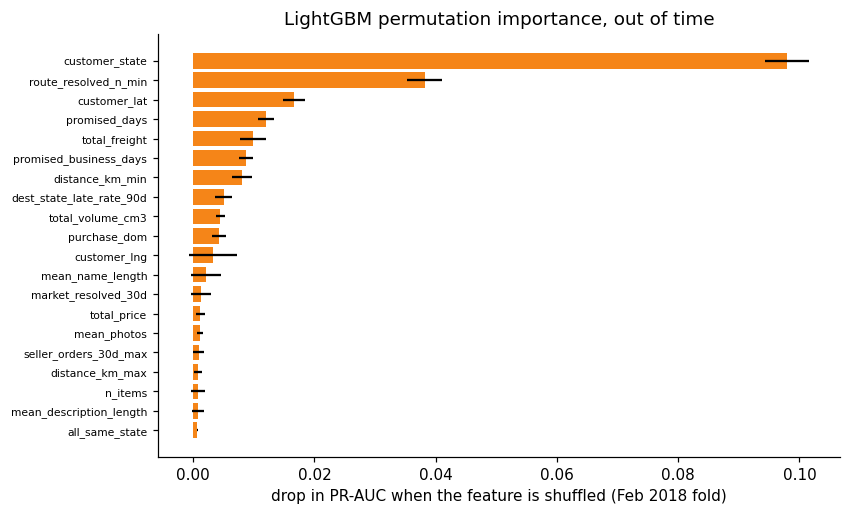

features with importance <= 0 (shuffling does not hurt): ['n_payment_types', 'uses_voucher', 'black_friday_period', 'any_zero_freight', 'purchase_month', 'purchase_is_weekend', 'any_category_missing', 'seller_geo_imputed', 'n_categories', 'seller_cold_start', 'customer_prior_orders', 'seller_prior_orders_min', 'customer_geo_imputed', 'total_weight_g', 'n_products', 'seller_resolved_n_min', 'n_seller_states', 'max_installments', 'max_weight_g', 'max_item_price', 'freight_ratio', 'max_volume_cm3', 'purchase_hour', 'main_payment_type', 'holiday_within_7d', 'seller_orders_7d_max', 'route_late_rate_max', 'main_category', 'seller_late_rate_max', 'holidays_in_promise', 'market_late_rate_30d', 'dest_state_late_rate']


In [7]:
lasso = make_model("logreg", FULL, C=0.02, l1_ratio=1.0).fit(TRAIN[FULL], TRAIN.late_day)
coef = pd.Series(lasso.named_steps["clf"].coef_[0], index=lasso.named_steps["pre"].get_feature_names_out())
def origin(col):
    for f in sorted(FULL, key=len, reverse=True):
        if col == f or col.startswith(f + "_") or col == f"missingindicator_{f}":
            return f
    return col
by_feature = coef.abs().groupby(coef.index.map(origin)).max()
zeroed = sorted(by_feature[by_feature == 0].index)
print(f"lasso (C=0.02): {int((coef != 0).sum())} of {len(coef)} design columns non-zero; "
      f"{len(zeroed)} of {len(FULL)} features fully zeroed:\n  {zeroed}")

tr_idx, va_idx = folds[-1]
lg = make_model("lgbm", FULL).fit(TP[FULL].iloc[tr_idx], TP.late_day.iloc[tr_idx])
pi = permutation_importance(lg, TP[FULL].iloc[va_idx], TP.late_day.iloc[va_idx].astype(int), scoring="average_precision",
                            n_repeats=5, random_state=C.SEED, n_jobs=5)
perm = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=FULL).sort_values("importance", ascending=False)
perm.to_csv(RESULTS / "04_permutation_importance_feb2018.csv")
fig, ax = plt.subplots(figsize=(8, 5))
top = perm.head(20)[::-1]
ax.barh(top.index, top.importance, xerr=top.sd, color="#F58518"); ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("drop in PR-AUC when the feature is shuffled (Feb 2018 fold)"); ax.set_title("LightGBM permutation importance, out of time")
save("permutation_importance"); plt.show()
print("features with importance <= 0 (shuffling does not hurt):", perm.index[perm.importance <= 0].tolist())

**Finding.** The three lenses agree on the strong groups and the weak ones.
* **Promise, geography and calendar carry the signal.** Removing the promise features hurts both learners (−0.012 and −0.010, worse in every fold). Removing geography (−0.016) or calendar (−0.013) hurts LightGBM in 3–4 of the 4 folds.
* **Product features are noise.** Removing them *improves* both learners (+0.005 LightGBM, +0.001 logistic regression). The lasso zeroes weight and volume completely, and permutation importance puts `main_category`, weights and volumes at about 0.
* **Redundant near-duplicates** also score slightly better when removed (+0.002 and +0.001).
* **Seller history and market rates** give small, mixed effects (|Δ| ≤ 0.003), consistent with the EDA.
* **`purchase_month`:** removing it costs logistic regression 0.020 and LightGBM 0.004. This contradicts the EDA and is investigated in section 5.

**Decision.** Product features are a drop candidate, checked together with `purchase_month` in section 5. Promise, calendar, geography, basket and payment stay; payment passes its ablation gate, since removing it hurt both learners in 3 of 4 folds. All history groups stay too: their effects are small or mixed, and the EDA shows that seller differences are real.

## 5. The `purchase_month` paradox: within-month vs pooled scores

The ablation says removing `purchase_month` *hurts*, against the EDA's memorisation warning. There's a catch. Every validation fold is a single month, so within a fold `purchase_month` is the same for every row and **cannot change the ranking inside that fold**. Whatever it adds must come from training: the month dummies act as a time "fixed effect" that soaks up month-level swings while the other weights are learned.

A deployed model ranks orders **across** months, so the fold predictions are also pooled into one ranking. Pooled PR-AUC and the Brier score measure exactly what a memorised month would damage. Candidate feature sets are compared on all three numbers.

In [8]:
va_all = np.concatenate([va for _, va in abl_folds]); y_all = TP.late_day.to_numpy()[va_all]
PRODUCT = FEATURES.index[FEATURES.group == "product"].tolist()
cands = {
    "full (57)": FULL,
    "− purchase_month": [f for f in FULL if f != "purchase_month"],
    "− month − redundant": [f for f in FULL if f not in REDUNDANT + ["purchase_month"]],
    "− month − product": [f for f in FULL if f not in PRODUCT + ["purchase_month"]],
    "− month − product − redundant": [f for f in FULL if f not in PRODUCT + REDUNDANT + ["purchase_month"]],
}
pool_rows = []
for learner in ["logreg", "lgbm"]:
    for name, feats in cands.items():
        preds = walk_forward_predict(make_model(learner, feats), TP, abl_folds, feats, n_jobs=4)
        pool_rows.append({"learner": learner, "feature set": name, "n": len(feats),
                          "within_month_pr_auc": np.mean([average_precision_score(y, p) for y, p in zip(y_folds[1:], preds)]),
                          "pooled_pr_auc": average_precision_score(y_all, np.concatenate(preds)),
                          "pooled_brier": brier_score_loss(y_all, np.concatenate(preds))})
pool = pd.DataFrame(pool_rows)
pool.to_csv(RESULTS / "04_pooled_vs_within.csv", index=False)
pool.pivot(index="feature set", columns="learner", values=["within_month_pr_auc", "pooled_pr_auc", "pooled_brier"]).loc[list(cands)].round(4)

within_month_pr_auc         pooled_pr_auc         pooled_brier        
learner                                      lgbm  logreg          lgbm  logreg         lgbm  logreg
feature set                                                                                         
full (57)                                  0.1606  0.1666        0.1458  0.1226       0.0929  0.0927
− purchase_month                           0.1568  0.1467        0.1495  0.1546       0.0927  0.0920
− month − redundant                        0.1555  0.1475        0.1515  0.1558       0.0922  0.0921
− month − product                          0.1595  0.1474        0.1586  0.1550       0.0921  0.0920
− month − product − redundant              0.1538  0.1482        0.1499  0.1558       0.0922  0.0920

**Finding.** The paradox resolves cleanly. With `purchase_month`, within-month PR-AUC is higher (logistic regression 0.167 against 0.147), but **pooled PR-AUC collapses** (logistic regression 0.123 against 0.155; LightGBM 0.146 against 0.150) and the Brier score is worse for both. The month dummies shift whole months up or down by what happened in that calendar month in the training years, which is exactly the memorisation the EDA predicted.

Once the month is removed, also dropping the product group gives the best LightGBM on all three measures (within-month 0.160, pooled 0.159, Brier 0.0921), and logistic regression stays within 0.001 of its best. Dropping the redundant group as well hurts LightGBM (pooled 0.150), so those features stay.

**Decision.** Drop `purchase_month` and the 9 product features, leaving 47 features at this point. Section 6 removes five more.

## 6. Stationarity audit: features that are really clocks

> **Disclosure.** This section was added *after* a first evaluation of the 47-feature models on the test period (notebook 07 keeps those first-pass numbers). There, every tuned model lost to the five-feature baseline. Diagnosing why used **no test labels**: only the purchase dates and an adversarial classifier that tries to tell training-period rows from validation rows. The test set has therefore been looked at twice, and the final test numbers should be read with that in mind.

A feature can carry real signal about an *order*, or it can quietly encode *when* the order was placed. The second kind is dangerous. It works while the trend it tracks continues, then fails when the trend reverses. Two label-free checks find it:
1. **Spearman correlation with the purchase date** inside the training period.
2. **Adversarial validation:** a LightGBM trained to separate training-period rows from validation rows. An AUC near 0.5 means the periods look alike; an AUC near 1 means some features identify the period.

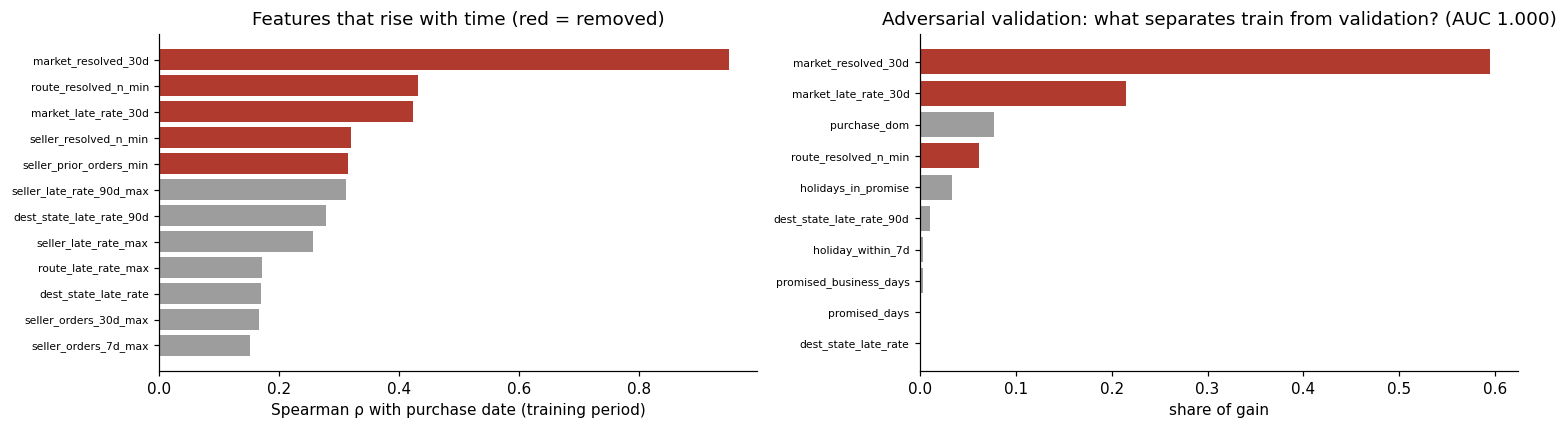

adversarial AUC with 47 features: 1.000 | after removing the 5 clock features: 1.000
top separating features after removal: {'dest_state_late_rate_90d': 0.346, 'seller_late_rate_90d_max': 0.128, 'dest_state_late_rate': 0.11, 'holidays_in_promise': 0.086, 'purchase_dom': 0.083}


,learner,feature set,within_month_pr_auc,pooled_pr_auc,val_pr_auc
0,logreg,47 features,0.1474,0.1550,0.2242
1,logreg,42 (clocks removed),0.1515,0.1601,0.2340
2,lgbm,47 features,0.1595,0.1586,0.1958
3,lgbm,42 (clocks removed),0.1409,0.1478,0.1876


In [9]:
F47 = [f for f in FULL if f not in PRODUCT + ["purchase_month"]]
t_days = (TP.order_purchase_timestamp - TP.order_purchase_timestamp.min()).dt.days
from scipy import stats
rho = pd.Series({f: stats.spearmanr(TP[f], t_days, nan_policy="omit")[0] for f in F47 if FEATURES.loc[f, "kind"] == "num"})
import lightgbm as lgb
def adversarial(feats):
    A = pd.concat([TP.assign(is_val=0), S["val"].assign(is_val=1)], ignore_index=True)
    X = tree_preprocessor(feats).fit(A[feats], A.is_val).transform(A[feats])
    idx = np.random.default_rng(C.SEED).permutation(len(A)); a, b = idx[: int(0.7 * len(A))], idx[int(0.7 * len(A)):]
    m = lgb.LGBMClassifier(n_estimators=200, random_state=C.SEED, n_jobs=8, verbose=-1).fit(X.iloc[a], A.is_val.iloc[a])
    gain = pd.Series(m.booster_.feature_importance("gain"), index=X.columns)
    return roc_auc_score(A.is_val.iloc[b], m.predict_proba(X.iloc[b])[:, 1]), (gain / gain.sum()).sort_values(ascending=False)
auc47, gain47 = adversarial(F47)
CLOCK = ["market_late_rate_30d", "market_resolved_30d", "route_resolved_n_min", "seller_resolved_n_min", "seller_prior_orders_min"]
F42 = [f for f in F47 if f not in CLOCK]
auc42, gain42 = adversarial(F42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r = rho.reindex(rho.abs().sort_values(ascending=False).index).head(12)[::-1]
axes[0].barh(r.index, r, color=np.where(r.index.isin(CLOCK), "#B03A2E", "#9D9D9D")); axes[0].tick_params(axis="y", labelsize=7)
axes[0].set_xlabel("Spearman ρ with purchase date (training period)"); axes[0].set_title("Features that rise with time (red = removed)")
g = gain47.head(10)[::-1]
axes[1].barh(g.index, g, color=np.where(g.index.isin(CLOCK), "#B03A2E", "#9D9D9D")); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_xlabel("share of gain"); axes[1].set_title(f"Adversarial validation: what separates train from validation? (AUC {auc47:.3f})")
plt.tight_layout(); save("stationarity_audit"); plt.show()
print(f"adversarial AUC with 47 features: {auc47:.3f} | after removing the 5 clock features: {auc42:.3f}")
print("top separating features after removal:", gain42.head(5).round(3).to_dict())

stat_rows = []
for learner in ["logreg", "lgbm"]:
    for name, feats in [("47 features", F47), ("42 (clocks removed)", F42)]:
        preds = walk_forward_predict(make_model(learner, feats), TP, abl_folds, feats, n_jobs=4)
        m = make_model(learner, feats).fit(TRAIN[feats], TRAIN.late_day)
        stat_rows.append({"learner": learner, "feature set": name,
                          "within_month_pr_auc": np.mean([average_precision_score(y, p) for y, p in zip(y_folds[1:], preds)]),
                          "pooled_pr_auc": average_precision_score(y_all, np.concatenate(preds)),
                          "val_pr_auc": average_precision_score(S["val"].late_day, m.predict_proba(S["val"][feats])[:, 1])})
stat = pd.DataFrame(stat_rows)
stat.to_csv(RESULTS / "04_stationarity_audit.csv", index=False)
pd.Series(rho).round(3).rename("spearman_with_date").to_csv(RESULTS / "04_time_correlation.csv")
stat.round(4)

**Finding.** `market_resolved_30d` is effectively a clock: its correlation with the purchase date is ρ = 0.95, because order volume grew steadily. With the 47 features, the adversarial classifier separates training-period rows from validation rows **perfectly (AUC 1.000)**, and 59% of its gain comes from `market_resolved_30d` and another 22% from `market_late_rate_30d`. These features differ by *date*, not by order.

After the five clock features are removed, the periods are still perfectly separable, but by different features. The top separators become the 90-day destination-state and seller late rates (35% and 13% of gain) and holiday counts. Those changed because the real risk and the calendar changed between periods, and they still differ from order to order. That is genuine drift, which no feature set can remove; it is handled by recalibration and retraining in notebook 08.

The walk-forward evidence is **mixed**. Logistic regression improves on every measure (within-month 0.147 → 0.152, pooled 0.155 → 0.160, validation 0.224 → 0.234). LightGBM gets worse (pooled 0.159 → 0.148, validation 0.196 → 0.188). This is expected: inside the training window, volume and lateness rose *together* (Black Friday, Feb 2018), so a clock still "predicts" there. It only fails once the trend reverses, which the training window never shows.

**Decision.** Drop the five clock features: `market_late_rate_30d` and `market_resolved_30d` (market-level, identical for every order on a given day), and `route_resolved_n_min`, `seller_resolved_n_min` and `seller_prior_orders_min` (cumulative counts that grow with the marketplace's age). The reason is a design principle, that a feature should describe the order and not the calendar, backed by the label-free audit. The CV numbers do not justify it on their own. As disclosed above, the issue was noticed on a first look at the test set.

## 7. The final feature set

In [10]:
final = model_features()
print(f"{len(final)} features kept; dropped ({len(DROPPED_AFTER_ABLATION)}):")
for f, why in DROPPED_AFTER_ABLATION.items():
    print(f"  - {f}")
print()
print("final features by group:", FEATURES.loc[final].group.value_counts().to_dict())

42 features kept; dropped (15):
  - purchase_month
  - total_weight_g
  - max_weight_g
  - total_volume_cm3
  - max_volume_cm3
  - mean_photos
  - mean_description_length
  - mean_name_length
  - main_category
  - any_category_missing
  - market_late_rate_30d
  - market_resolved_30d
  - route_resolved_n_min
  - seller_resolved_n_min
  - seller_prior_orders_min

final features by group: {'geography': 10, 'basket': 9, 'history': 9, 'calendar': 6, 'promise': 4, 'payment': 4}


The final set has **42 features**: geography 10, basket 9, history 9, calendar 6, promise 4, payment 4. Notebook 06 saves this list to `models/task_a_features.json`. Notebooks 07–09 and `predict.py` read it from there, so nothing downstream hard-codes feature names.

In [11]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 1218.8s | final RSS 577 MB
